<a href="https://colab.research.google.com/github/ryifanay-wq/REGRESI_NAYLA/blob/main/regresi_aktv_4_nayla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


REGRESI LINEAR BERGANDA IPM
Cakupan: Kota Palembang (2014-2024)
Jumlah data: 11
Derajat bebas: 7

           Koefisien  Std.Err       t  p-value
Konstanta    73.8864  14.0557  5.2567   0.0012
DAU_Grant    -0.0577   0.0730 -0.7902   0.4553
PAD           0.0521   0.0614  0.8484   0.4243
DAK_Fisik    -0.0212   0.1416 -0.1495   0.8853

R-squared     : 0.1982
Adjusted R²   : -0.1455
F hitung      : 0.5766
RMSE          : 7.6434

Persamaan regresi:
IPM = 73.8864 - 0.0577 DAU_Grant + 0.0521 PAD - 0.0212 DAK_Fisik


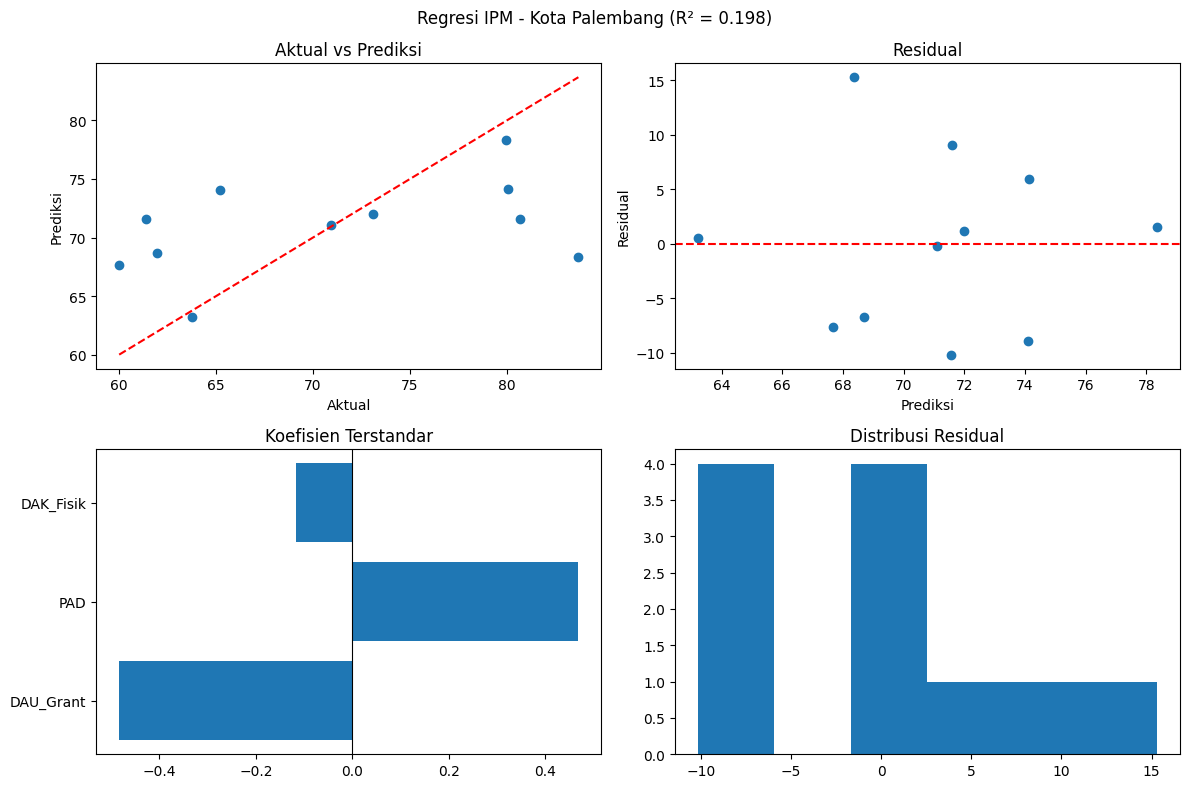

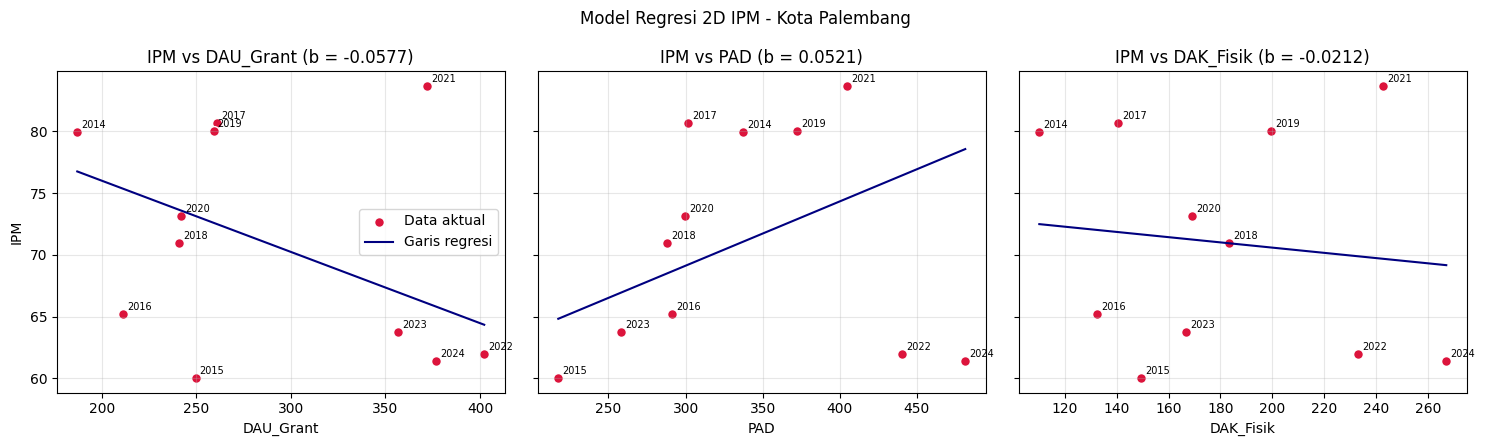

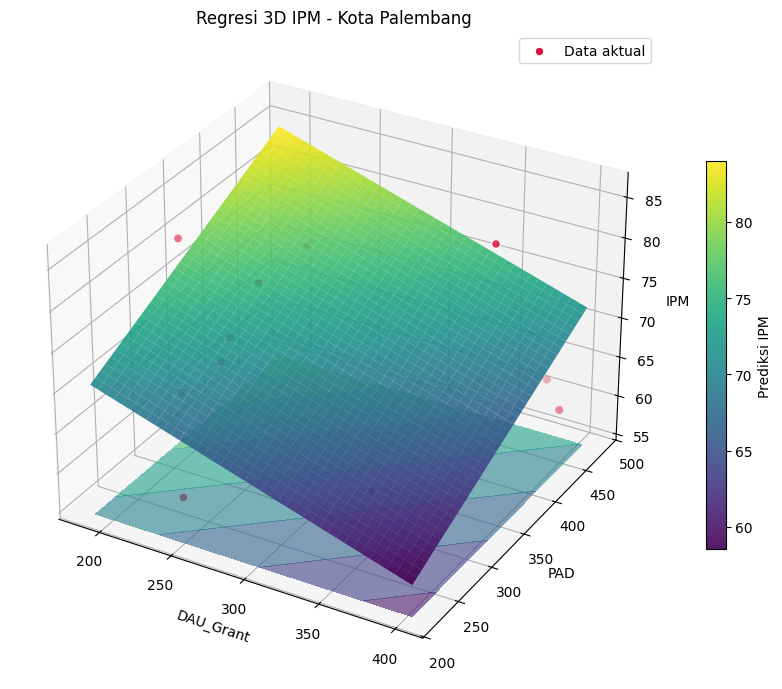


File grafik tersimpan di: /content


In [19]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NAMA_FILE = "/content/databesar.csv"
if not os.path.isfile(NAMA_FILE):
    NAMA_FILE = "/mnt/user-data/uploads/databesar.csv"
FOLDER_OUT = "/content" if os.path.isdir("/content") else "/mnt/user-data/outputs"

KOTA = "Kota Palembang"

Y = "IPM"
X = ["DAU_Grant", "PAD", "DAK_Fisik"]


def p_value(t, db):
    c = math.exp(
        math.lgamma((db + 1) / 2)
        - math.lgamma(db / 2)
    ) / math.sqrt(db * math.pi)

    x = np.linspace(0, abs(t), 20001)
    f = c * (1 + x**2 / db)**(-(db + 1) / 2)
    luas = np.sum((f[1:] + f[:-1]) / 2 * np.diff(x))

    return max(0.0, 1 - 2 * luas)


def regresi(X_data, y):
    n, k = X_data.shape
    A = np.column_stack([np.ones(n), X_data])

    b = np.linalg.lstsq(A, y, rcond=None)[0]
    yhat = A @ b
    e = y - yhat

    db = n - k - 1
    sse = e @ e
    sst = np.sum((y - y.mean())**2)

    if db <= 0 or sst == 0:
        raise ValueError("Data tidak cukup atau nilai Y konstan.")

    r2 = 1 - sse / sst
    r2_adj = 1 - (1 - r2) * (n - 1) / db
    s2 = sse / db

    se = np.sqrt(np.diag(s2 * np.linalg.pinv(A.T @ A)))
    t = b / se
    p = [p_value(a, db) for a in t]

    f = ((sst - sse) / len(X)) / s2
    rmse = math.sqrt(sse / n)

    return b, se, t, p, r2, r2_adj, f, rmse, yhat, e, db


def grafik_2d(data, b, x_nama, y_nama):
    # Satu panel per variabel X; variabel X lain ditahan pada rata-rata
    X_data = data[x_nama].values.astype(float)
    y = data[y_nama].values.astype(float)
    rata = X_data.mean(axis=0)

    fig, ax = plt.subplots(1, len(x_nama), figsize=(15, 4.5), sharey=True)
    fig.suptitle(f"Model Regresi 2D {y_nama} - {KOTA}")

    for i, nama in enumerate(x_nama):
        garis_x = np.linspace(X_data[:, i].min(), X_data[:, i].max(), 100)
        titik_tetap = np.tile(rata, (100, 1))
        titik_tetap[:, i] = garis_x
        garis_y = b[0] + titik_tetap @ b[1:]

        ax[i].scatter(X_data[:, i], y, color="crimson", edgecolor="white", s=50, label="Data aktual")
        for th, xx, yy in zip(data["Tahun"], X_data[:, i], y):
            ax[i].annotate(str(th), (xx, yy), fontsize=7, xytext=(3, 3), textcoords="offset points")
        ax[i].plot(garis_x, garis_y, color="navy", label="Garis regresi")
        ax[i].set_xlabel(nama)
        ax[i].set_title(f"{y_nama} vs {nama} (b = {b[1 + i]:.4f})")
        ax[i].grid(alpha=0.3)
    ax[0].set_ylabel(y_nama)
    ax[0].legend()

    plt.tight_layout()
    plt.savefig(f"{FOLDER_OUT}/hasil_regresi_2d_palembang.png", dpi=150)
    plt.show()


def grafik_3d(data, b, x_nama, y_nama):
    # Sumbu X1 (DAU_Grant) dan X2 (PAD); X3 (DAK_Fisik) ditahan pada rata-rata
    a, c, w = 0, 1, 2

    X_data = data[x_nama].values.astype(float)
    y = data[y_nama].values.astype(float)

    x1, x2, x3 = X_data[:, a], X_data[:, c], X_data[:, w]

    g1, g2 = np.meshgrid(
        np.linspace(x1.min(), x1.max(), 40),
        np.linspace(x2.min(), x2.max(), 40)
    )

    bidang = (
        b[0] + b[1 + a] * g1 + b[1 + c] * g2 + b[1 + w] * x3.mean()
    )

    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")

    bawah = min(y.min(), bidang.min())
    atas = max(y.max(), bidang.max())
    bawah -= 0.15 * (atas - bawah)

    perm = ax.plot_surface(g1, g2, bidang, cmap="viridis", alpha=0.9, linewidth=0)
    ax.contourf(g1, g2, bidang, zdir="z", offset=bawah, cmap="viridis", alpha=0.6)
    ax.scatter(x1, x2, y, color="crimson", edgecolor="white", s=40, label="Data aktual")

    ax.set_zlim(bawah, None)
    ax.set_xlabel(x_nama[a])
    ax.set_ylabel(x_nama[c])
    ax.set_zlabel(y_nama)
    ax.set_title(f"Regresi 3D {y_nama} - {KOTA}")
    ax.legend()
    fig.colorbar(perm, ax=ax, shrink=0.6, label=f"Prediksi {y_nama}")

    plt.tight_layout()
    plt.savefig(f"{FOLDER_OUT}/hasil_regresi_3d_palembang.png", dpi=150)
    plt.show()


def main():
    if not os.path.isfile(NAMA_FILE):
        print("File CSV belum di-upload.")
        return

    df = pd.read_csv(NAMA_FILE)
    df.columns = df.columns.str.strip()

    kolom_wajib = ["Kota", "Tahun"] + X + [Y]
    kurang = [kolom for kolom in kolom_wajib if kolom not in df.columns]
    if kurang:
        print("Kolom tidak ditemukan:", kurang)
        return

    # Filter khusus Palembang
    df = df[df["Kota"].str.strip() == KOTA]
    data = df[["Kota", "Tahun", Y] + X].copy()

    for kolom in [Y] + X:
        data[kolom] = pd.to_numeric(data[kolom], errors="coerce")

    data = data.dropna(subset=[Y] + X).sort_values("Tahun")

    if len(data) < 5:
        print("Data tidak cukup untuk regresi.")
        return

    X_data = data[X].values.astype(float)
    y = data[Y].values.astype(float)

    b, se, t, p, r2, r2_adj, f, rmse, yhat, e, db = regresi(X_data, y)

    hasil = pd.DataFrame(
        {"Koefisien": b, "Std.Err": se, "t": t, "p-value": p},
        index=["Konstanta"] + X
    )

    print(f"\nREGRESI LINEAR BERGANDA {Y}")
    print(f"Cakupan: {KOTA} ({data['Tahun'].min()}-{data['Tahun'].max()})")
    print(f"Jumlah data: {len(y)}")
    print(f"Derajat bebas: {db}\n")
    print(hasil.round(4))

    print(f"\nR-squared     : {r2:.4f}")
    print(f"Adjusted R²   : {r2_adj:.4f}")
    print(f"F hitung      : {f:.4f}")
    print(f"RMSE          : {rmse:.4f}")

    rumus = f"{Y} = {b[0]:.4f}"
    for koef, nama in zip(b[1:], X):
        tanda = "+" if koef >= 0 else "-"
        rumus += f" {tanda} {abs(koef):.4f} {nama}"
    print("\nPersamaan regresi:")
    print(rumus)

    # Grafik diagnostik
    fig, ax = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle(f"Regresi {Y} - {KOTA} (R² = {r2:.3f})")

    ax[0, 0].scatter(y, yhat)
    batas = [min(y.min(), yhat.min()), max(y.max(), yhat.max())]
    ax[0, 0].plot(batas, batas, "r--")
    ax[0, 0].set_xlabel("Aktual")
    ax[0, 0].set_ylabel("Prediksi")
    ax[0, 0].set_title("Aktual vs Prediksi")

    ax[0, 1].scatter(yhat, e)
    ax[0, 1].axhline(0, color="r", linestyle="--")
    ax[0, 1].set_xlabel("Prediksi")
    ax[0, 1].set_ylabel("Residual")
    ax[0, 1].set_title("Residual")

    beta_std = b[1:] * X_data.std(axis=0, ddof=1) / y.std(ddof=1)
    ax[1, 0].barh(X, beta_std)
    ax[1, 0].axvline(0, color="k", linewidth=0.8)
    ax[1, 0].set_title("Koefisien Terstandar")

    ax[1, 1].hist(e, bins=6)
    ax[1, 1].set_title("Distribusi Residual")

    plt.tight_layout()
    plt.savefig(f"{FOLDER_OUT}/hasil_regresi_palembang.png", dpi=150)
    plt.show()

    grafik_2d(data, b, X, Y)
    grafik_3d(data, b, X, Y)

    print("\nFile grafik tersimpan di:", FOLDER_OUT)


main()